In [1]:
2+2

4

In [2]:
import os
# Creiamo la cartella sul disco grande se non esiste
os.makedirs("/opt/dlami/nvme/huggingface", exist_ok=True)
# Diciamo ad Hugging Face di scaricare tutto lì dentro
os.environ["HF_HOME"] = "/opt/dlami/nvme/huggingface"

# Login in hugginFace

In [3]:
from huggingface_hub import login
login()

# Import data

In [4]:
import pandas as pd

df = pd.read_csv('Dataset/newDataframeWithOldCleanedPoliticsVersion.csv')

df = df.reset_index(drop=True)
df

,url,title,text,authors,domain,score,country,language,topics,paywall,opinion_advocacy,label
0,https://nemontananews.com/stories/670532029-1-...,1 gas station in cities throughout Phillips Co...,Federal Energy Regulatory Commission (FERC) Ch...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
1,https://nemontananews.com/stories/670175501-mc...,McCone County: Income Maintenance dependency r...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
2,https://nemontananews.com/stories/670489322-da...,"Daniels County residents received $13,488 per ...","John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
3,https://nemontananews.com/stories/670175454-da...,Daniels County: Income Maintenance made up 0.8...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
4,https://nemontananews.com/stories/670413125-wh...,Where could drivers find the cheapest gas in c...,Federal Energy Regulatory Commission (FERC) Co...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...
19471,https://www.truthdig.com/articles/us-house-vot...,US House Vote Rolls Back Wetlands Regulations,The U.S. House voted Thursday to undo a Biden ...,NaN,truthdig.com,80.0,NaN,NaN,Political_news_or_commentary,NaN,NaN,3
19472,https://www.truthdig.com/articles/environmenta...,Environmental Racism in Canada,Informed nine months after the fact that its h...,NaN,truthdig.com,80.0,NaN,NaN,Political_news_or_commentary,NaN,NaN,3
19473,https://www.truthdig.com/articles/the-runaway-...,The Runaway Train of Corporate Greed,Thursday’s U.S. Senate hearing about the ongoi...,NaN,truthdig.com,80.0,NaN,NaN,Political_news_or_commentary,NaN,NaN,3
19474,https://www.truthdig.com/articles/ron-desantis...,Ron DeSantis’ Phantom War Against Voter Fraud,A new Florida law gives Gov.Ron DeSantis’ pros...,NaN,truthdig.com,80.0,NaN,NaN,Political_news_or_commentary,NaN,NaN,3


# Create folds

In [5]:
import random
import numpy as np
import pandas as pd
import pickle
import os
from sklearn.model_selection import StratifiedKFold

# ── Seed ──────────────────────────────────────────────────────────────────────
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ── Parametri ─────────────────────────────────────────────────────────────────
LABEL_COL   = "label"
TEXT_COL    = "text"
DOMAIN_COL  = "domain"
N_SPLITS    = 5
OUTPUT_DIR  = "Results/Classification/folds"

# ── Label mapping ─────────────────────────────────────────────────────────────
df = df.copy().reset_index(drop=True)
unique_labels  = sorted(df[LABEL_COL].unique())
label_mapping  = {label: i for i, label in enumerate(unique_labels)}
df["mapped_label"] = df[LABEL_COL].map(label_mapping)
print(f"Detected {len(unique_labels)} unique labels: {unique_labels}")
print(f"Mapped labels: {label_mapping}")

# ── Creazione dei fold ────────────────────────────────────────────────────────
if DOMAIN_COL and DOMAIN_COL in df.columns:
    print(f"Using domain-level stratification on column '{DOMAIN_COL}'...")
    grouped         = df.groupby(DOMAIN_COL)
    domains         = list(grouped.groups.keys())
    stratify_labels = [group[1]["mapped_label"].mode()[0] for group in grouped]
    skf   = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    folds = []
    for train_idx, test_idx in skf.split(domains, stratify_labels):
        train_domains = [domains[i] for i in train_idx]
        test_domains  = [domains[i] for i in test_idx]
        train_df = df[df[DOMAIN_COL].isin(train_domains)].reset_index(drop=True)
        test_df  = df[df[DOMAIN_COL].isin(test_domains)].reset_index(drop=True)
        folds.append((train_df, test_df))
else:
    print("Using standard stratified splitting...")
    skf   = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    folds = [
        (df.iloc[train_idx].reset_index(drop=True),
         df.iloc[test_idx].reset_index(drop=True))
        for train_idx, test_idx in skf.split(df, df["mapped_label"])
    ]

# ── Salvataggio fold (solo train/test, identico al codice BERT) ───────────────
folds_out = []
for fold_idx, (train_df, test_df) in enumerate(folds):
    folds_out.append({
        "fold":  fold_idx + 1,
        "train": train_df.reset_index(drop=True),
        "test":  test_df.reset_index(drop=True),
    })
    print(f"Fold {fold_idx+1}: train={len(train_df)}, test={len(test_df)}")

# ── Salvataggio ───────────────────────────────────────────────────────────────
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Salva i fold come pickle (struttura completa)
folds_path = os.path.join(OUTPUT_DIR, "folds.pkl")
with open(folds_path, "wb") as f:
    pickle.dump(folds_out, f)
print(f"\nFolds saved to {folds_path}")

# Salva anche label_mapping per usarlo nel blocco 2
meta = {
    "label_mapping":  label_mapping,
    "unique_labels":  unique_labels,
    "label_col":      LABEL_COL,
    "text_col":       TEXT_COL,
    "random_seed":    RANDOM_SEED,
}
meta_path = os.path.join(OUTPUT_DIR, "meta.pkl")
with open(meta_path, "wb") as f:
    pickle.dump(meta, f)
print(f"Meta info saved to {meta_path}")

Detected 5 unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Mapped labels: {np.int64(0): 0, np.int64(1): 1, np.int64(2): 2, np.int64(3): 3, np.int64(4): 4}
Using domain-level stratification on column 'domain'...
Fold 1: train=15581, test=3895
Fold 2: train=15429, test=4047
Fold 3: train=15811, test=3665
Fold 4: train=15608, test=3868
Fold 5: train=15475, test=4001

Folds saved to Results/Classification/folds/folds.pkl
Meta info saved to Results/Classification/folds/meta.pkl


# mistral24b

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import random, gc, pickle, time, datetime, traceback
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, matthews_corrcoef, cohen_kappa_score
from transformers import BitsAndBytesConfig, AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model
import bitsandbytes as bnb
from tqdm import tqdm

# ── HARDWARE ──
torch.set_float32_matmul_precision('medium')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(RANDOM_SEED)
DEVICE = torch.device("cuda")

# ── PATHS ──
FOLDS_DIR = "Results/Classification/folds"
OUTPUT_DIR = "Results/Classification/mistral"
OUTPUT_CSV_PATH = os.path.join(OUTPUT_DIR, "24B_results.csv")
MODELS_SAVE_DIR = os.path.join(OUTPUT_DIR, "Models")
LOG_PATH = os.path.join(OUTPUT_DIR, "training_status.log")
os.makedirs(MODELS_SAVE_DIR, exist_ok=True)

def log_event(msg):
    ts = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    line = f"[{ts}] {msg}"
    print(line)
    with open(LOG_PATH, "a", buffering=1) as f: f.write(line + "\n")

log_event("="*70)
log_event("TRAINING SESSION STARTED")

# ── PARAMS ──
MODEL_ID = "mistralai/Mistral-Small-24B-Base-2501"
NUM_EPOCHS = 3
TRAIN_BATCH_SIZE = 6
EVAL_BATCH_SIZE = 48
GRADIENT_ACCUMULATION_STEPS = 5
MAX_SEQ_LENGTH = 1024
NUM_WORKERS = 3
USE_FLASH_ATTENTION = True
LOG_EVERY_N_ARTICLES = 60

def compute_metrics(true_list, preds_list):
    result = {}
    for avg in ["macro","micro","weighted"]:
        result[f"Precision_{avg}"] = precision_score(true_list, preds_list, average=avg, zero_division=0)
        result[f"Recall_{avg}"] = recall_score(true_list, preds_list, average=avg, zero_division=0)
        result[f"F1_{avg}"] = f1_score(true_list, preds_list, average=avg, zero_division=0)
    result["Accuracy"] = accuracy_score(true_list, preds_list)
    result["Balanced_Accuracy"] = balanced_accuracy_score(true_list, preds_list)
    result["MCC"] = matthews_corrcoef(true_list, preds_list)
    result["Cohen_Kappa"] = cohen_kappa_score(true_list, preds_list)
    result["Confusion_Matrix"] = str(confusion_matrix(true_list, preds_list).tolist())
    return result

if USE_FLASH_ATTENTION:
    try: import flash_attn; ATTN_IMPL = "flash_attention_2"; log_event("✅ Flash Attention ENABLED")
    except: ATTN_IMPL = "eager"; USE_FLASH_ATTENTION=False; log_event("⚠️ Flash Attention NOT available")
else: ATTN_IMPL = "eager"

with open(os.path.join(FOLDS_DIR,"folds.pkl"),"rb") as f: folds_with_val = pickle.load(f)
with open(os.path.join(FOLDS_DIR,"meta.pkl"),"rb") as f: meta = pickle.load(f)
TEXT_COL = meta["text_col"]; num_labels = len(meta["unique_labels"]); ID_COL = "id"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(texts, truncation=True, padding=False, max_length=MAX_SEQ_LENGTH)
        self.labels = labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k,v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

# ── RIPRESA AUTOMATICA ──
if os.path.exists(OUTPUT_CSV_PATH):
    existing_df = pd.read_csv(OUTPUT_CSV_PATH)
    all_fold_results = existing_df.to_dict('records')
    completed_folds = set(existing_df['Fold'].tolist())
    log_event(f"📂 Trovato CSV esistente - Fold completati: {sorted(completed_folds)}")
else:
    all_fold_results = []
    completed_folds = set()

try:
    for fold_data in folds_with_val:
        fold_num = fold_data["fold"]

        # SALTA SE GIÀ FATTO
        if fold_num in completed_folds:
            log_event(f"⏭️ Salto Fold {fold_num} (già completato)")
            continue

        log_event(f"🚀 STARTING FOLD {fold_num}")
        train_df, test_df = fold_data["train"], fold_data["test"]
        train_ds = TextDataset(train_df[TEXT_COL].astype(str).tolist(), train_df["mapped_label"].tolist())
        test_ds = TextDataset(test_df[TEXT_COL].astype(str).tolist(), test_df["mapped_label"].tolist())

        collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8)
        train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
            pin_memory=True, persistent_workers=True, prefetch_factor=4, collate_fn=collator)
        eval_loader = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, num_workers=NUM_WORKERS,
            pin_memory=True, persistent_workers=True, prefetch_factor=4, collate_fn=collator)

        bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16)
        base_model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_ID, quantization_config=bnb_config, num_labels=num_labels,
            device_map="auto", attn_implementation=ATTN_IMPL, dtype=torch.bfloat16)
        base_model.config.pad_token_id = tokenizer.pad_token_id

        model = prepare_model_for_kbit_training(base_model, use_gradient_checkpointing=False)
        model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32,
            target_modules=["q_proj","k_proj","v_proj","o_proj"], task_type="SEQ_CLS"))
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.config.use_cache = False

        optimizer = bnb.optim.AdamW8bit(model.parameters(), lr=2e-5)
        criterion = torch.nn.CrossEntropyLoss()

        model.train()
        for epoch in range(NUM_EPOCHS):
            total_loss = 0; optimizer.zero_grad(set_to_none=True)
            start_time = time.time(); articles_seen = 0; total_steps = len(train_loader)
            log_event(f"FOLD {fold_num} EPOCH {epoch+1}/{NUM_EPOCHS} START")
            for step, batch in enumerate(tqdm(train_loader, desc=f"Fold{fold_num} Ep{epoch+1}")):
                batch = {k: v.to(DEVICE, non_blocking=True) for k,v in batch.items()}
                outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                loss = criterion(outputs.logits, batch["labels"]) / GRADIENT_ACCUMULATION_STEPS
                loss.backward()
                if (step+1) % GRADIENT_ACCUMULATION_STEPS == 0:
                    optimizer.step(); optimizer.zero_grad(set_to_none=True)
                total_loss += loss.item(); articles_seen += batch["input_ids"].size(0)
                if articles_seen % LOG_EVERY_N_ARTICLES < TRAIN_BATCH_SIZE or step == total_steps-1:
                    percent = (step+1)/total_steps*100
                    eta = (time.time()-start_time)/(step+1)*(total_steps-step-1)/60
                    gpu_mem = torch.cuda.memory_allocated()/1024**3
                    log_event(f"STATUS F{fold_num} E{epoch+1} | {percent:.1f}% | Loss {loss.item()*GRADIENT_ACCUMULATION_STEPS:.4f} | GPU {gpu_mem:.1f}GB | ETA {eta:.1f}min")
            log_event(f"FOLD {fold_num} EPOCH {epoch+1} COMPLETE | Avg Loss {total_loss/total_steps:.4f}")

        log_event(f"FOLD {fold_num} STARTING EVALUATION")
        model.eval(); preds_list, true_list = [], []
        with torch.no_grad():
            for batch in tqdm(eval_loader):
                batch = {k: v.to(DEVICE, non_blocking=True) for k,v in batch.items()}
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
                preds_list.extend(torch.argmax(logits,1).cpu().numpy().tolist())
                true_list.extend(batch["labels"].cpu().numpy().tolist())

        metrics = compute_metrics(true_list, preds_list)

        # FIX ID MANCANTE
        if ID_COL in test_df.columns:
            article_ids = test_df[ID_COL].astype(str).tolist()
        else:
            article_ids = test_df.index.astype(str).tolist()

        log_event(f"📊 FOLD {fold_num} RESULTS | Acc {metrics['Accuracy']:.4f} | F1_macro {metrics['F1_macro']:.4f}")

        # SALVA SUBITO MODELLO PRIMA DEL CSV
        model_path = os.path.join(MODELS_SAVE_DIR,f"fold_{fold_num}")
        model.save_pretrained(model_path)
        tokenizer.save_pretrained(model_path)

        fold_results = {"Fold":fold_num, "Flash_Attention":USE_FLASH_ATTENTION, **metrics,
            "Val_Article_IDs":str(article_ids), "Val_True_Labels":str(true_list), "Val_Predictions":str(preds_list)}
        all_fold_results.append(fold_results)
        pd.DataFrame(all_fold_results).to_csv(OUTPUT_CSV_PATH, index=False)
        log_event(f"💾 FOLD {fold_num} SALVATO")

        del model, base_model; torch.cuda.empty_cache(); gc.collect()

    log_event("🎉 ALL FOLDS COMPLETE")
except Exception as e:
    log_event(f"FATAL ERROR: {e}\n{traceback.format_exc()}")
    raise

[2026-04-21 08:13:07] ======================================================================
[2026-04-21 08:13:07] TRAINING SESSION STARTED
[2026-04-21 08:13:07] ✅ Flash Attention ENABLED
[2026-04-21 08:13:09] 📂 Trovato CSV esistente - Fold completati: [1]
[2026-04-21 08:13:09] ⏭️ Salto Fold 1 (già completato)
[2026-04-21 08:13:09] 🚀 STARTING FOLD 2


Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

/home/ubuntu/jupyter_env/lib/python3.12/site-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
MistralForSequenceClassification LOAD REPORT from: mistralai/Mistral-Small-24B-Base-2501
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-04-21 08:15:22] FOLD 2 EPOCH 1/3 START


Fold2 Ep1:   0%|                                                                                     | 0/2572 [00:00<?, ?it/s]`use_return_dict` is deprecated! Use `return_dict` instead!
Casting fp32 inputs back to torch.bfloat16 for flash-attn compatibility.
Fold2 Ep1:   0%|▎                                                                         | 10/2572 [01:04<4:31:21,  6.36s/it]

...

Fold2 Ep1:  84%|████████████████████████████████████████████████████████████▍           | 2160/2572 [3:47:30<42:47,  6.23s/it]

[2026-04-21 12:02:53] STATUS F2 E1 | 84.0% | Loss 0.0129 | GPU 13.5GB | ETA 43.4min


Fold2 Ep1:  84%|████████████████████████████████████████████████████████████▋           | 2170/2572 [3:48:31<39:10,  5.85s/it]

[2026-04-21 12:03:54] STATUS F2 E1 | 84.4% | Loss 0.6526 | GPU 13.5GB | ETA 42.3min


Fold2 Ep1:  85%|████████████████████████████████████████████████████████████▉           | 2176/2572 [3:49:08<40:45,  6.18s/it]

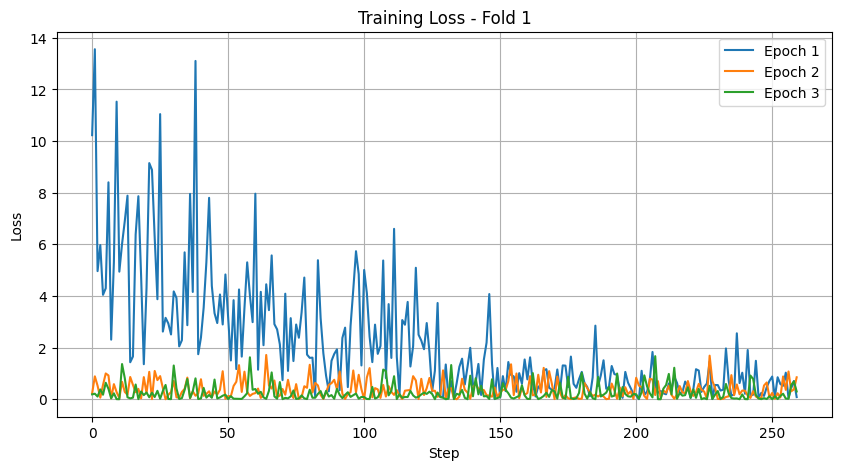

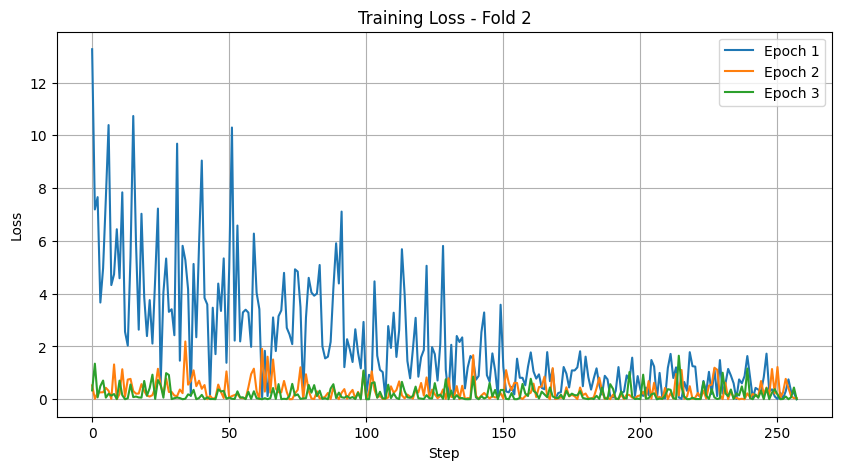

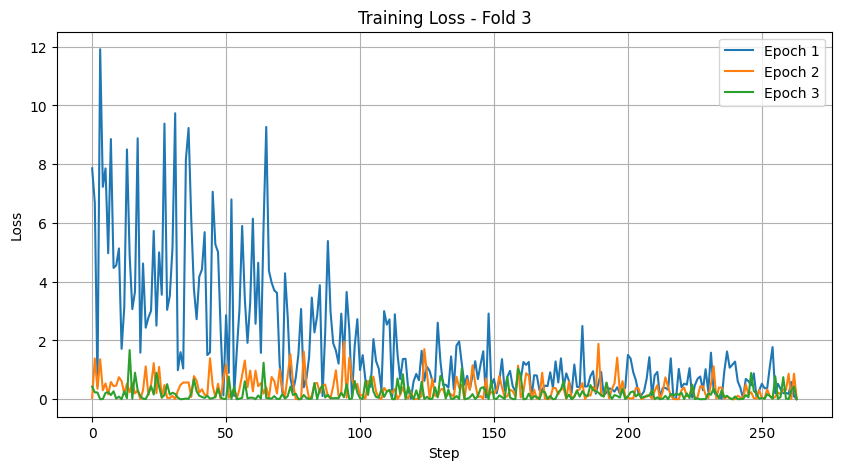

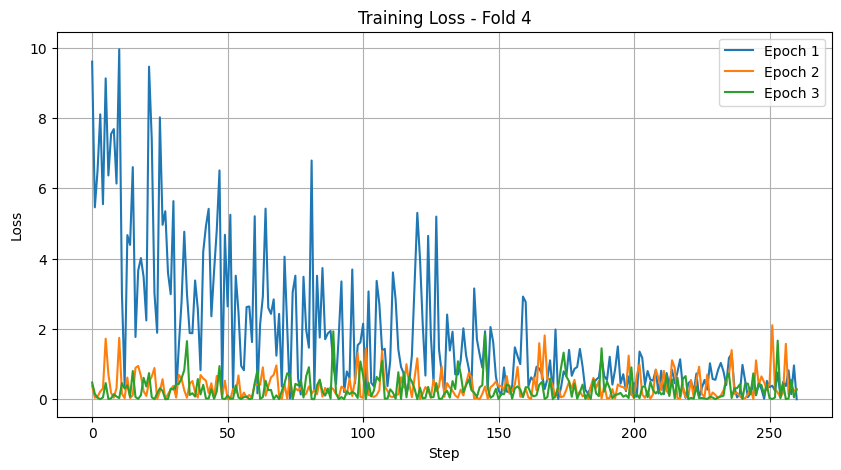

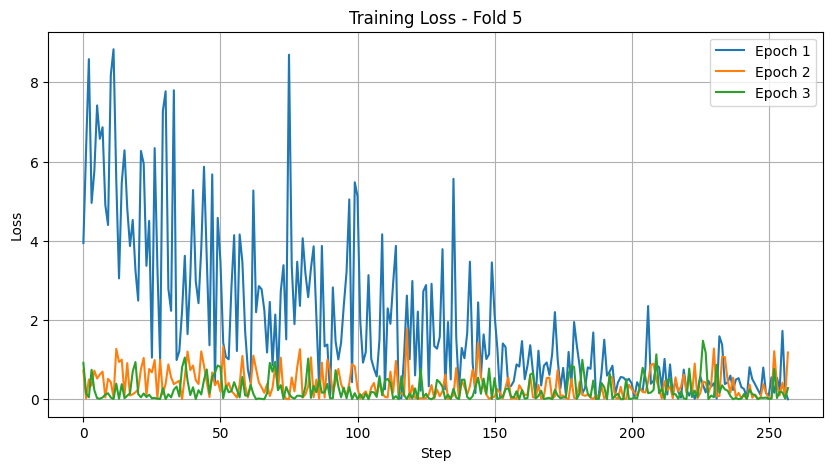

In [2]:
import re
import matplotlib.pyplot as plt
from collections import defaultdict

# === PATH AL FILE ===
log_file = "Results/Classification/mistral/mistralTrainingLoss.log"  # modifica se necessario

# === REGEX PER ESTRARRE I DATI ===
pattern = re.compile(
    r"STATUS F(\d+) E(\d+) .* Loss ([\d\.]+)"
)

# === STRUTTURA DATI ===
# fold -> epoch -> lista loss
data = defaultdict(lambda: defaultdict(list))

with open(log_file, "r") as f:
    for line in f:
        match = pattern.search(line)
        if match:
            fold = int(match.group(1))
            epoch = int(match.group(2))
            loss = float(match.group(3))
            
            data[fold][epoch].append(loss)

# === PLOT ===
for fold in sorted(data.keys()):
    plt.figure(figsize=(10, 5))
    
    for epoch in sorted(data[fold].keys()):
        losses = data[fold][epoch]
        steps = range(len(losses))
        
        plt.plot(steps, losses, label=f"Epoch {epoch}")
    
    plt.title(f"Training Loss - Fold {fold}")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    
    plt.show()

In [14]:
import re
import pandas as pd
import matplotlib
matplotlib.use("pdf")

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "DejaVu Serif",
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

# ── 1. Parsing ───────────────────────────────────────────────────────────────
LOG_PATH = "Results/Classification/mistral/mistralTrainingLoss.log"


pattern = re.compile(
    r"STATUS\s+F(\d+)\s+E(\d+)\s+\|.*?(\d+\.\d+)%.*?\|\s+Loss\s+([\d.]+)"
)

records = []
with open(LOG_PATH) as f:
    for line in f:
        m = pattern.search(line)
        if m:
            fold, epoch, pct, loss = int(m.group(1)), int(m.group(2)), float(m.group(3)), float(m.group(4))
            records.append({"fold": fold, "epoch": epoch, "pct": pct, "loss": loss})

df = pd.DataFrame(records)
df["global_pct"] = (df["epoch"] - 1) * 100 + df["pct"]

# ── 2. Rolling mean ──────────────────────────────────────────────────────────
WINDOW = 20

df_smooth = (
    df.sort_values(["fold", "global_pct"])
      .groupby("fold", group_keys=False)
      .apply(lambda g: g.assign(
          loss_smooth=g["loss"].rolling(WINDOW, min_periods=1, center=True).mean()
      ))
)

# ── 3. Stili ─────────────────────────────────────────────────────────────────
COLORS    = plt.rcParams["axes.prop_cycle"].by_key()["color"]
ep_colors = {1: "#4C72B0", 2: "#DD8452", 3: "#55A868"}
ep_hatch  = {1: "///",     2: "...",     3: "xxx"}

# ── 4. Plot ──────────────────────────────────────────────────────────────────
folds   = sorted(df["fold"].unique())
epochs  = sorted(df["epoch"].unique())
n_folds = len(folds)

fig, axes = plt.subplots(n_folds, 1, figsize=(14, 4.0 * n_folds), sharex=False)
if n_folds == 1:
    axes = [axes]

for ax, fold in zip(axes, folds):
    sub = df_smooth[df_smooth["fold"] == fold]

    y_max = sub["loss"].quantile(0.97)
    y_top = y_max * 1.22

    for ep in epochs:
        ep_sub = sub[sub["epoch"] == ep]
        if ep_sub.empty:
            continue
        x0, x1 = ep_sub["global_pct"].min(), ep_sub["global_pct"].max()
        ax.axvspan(x0, x1, alpha=0.07,
                   color=ep_colors[ep], hatch=ep_hatch[ep],
                   edgecolor=ep_colors[ep], linewidth=0.0)

    # Raw loss — grigio scuro, più visibile
    ax.plot(sub["global_pct"], sub["loss"],
            color="#555555", alpha=0.55, linewidth=0.9,
            label="Raw loss" if fold == folds[0] else "")

    # Smoothed
    ax.plot(sub["global_pct"], sub["loss_smooth"],
            color=COLORS[(fold - 1) % len(COLORS)], linewidth=1.8,
            label=f"Smoothed (w={WINDOW})" if fold == folds[0] else "")

    for ep_boundary in [100, 200]:
        if ep_boundary < sub["global_pct"].max():
            ax.axvline(ep_boundary, color="black", linewidth=0.8,
                       linestyle="--", alpha=0.5)

    ax.set_ylim(bottom=0, top=y_top)

    for ep in epochs:
        ep_sub = sub[sub["epoch"] == ep]
        if ep_sub.empty:
            continue
        avg   = ep_sub["loss"].mean()
        x_mid = ep_sub["global_pct"].mean()
        ax.text(x_mid, y_max * 1.05,
                f"mu={avg:.3f}", ha="center", va="bottom", fontsize=10,
                color=ep_colors[ep], fontweight="bold")

    ax.set_title(f"Fold {fold}", fontweight="bold", fontsize=13)
    ax.set_ylabel("Loss")
    ax.set_xlabel("Global progress (% across epochs)")
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(
        lambda x, _: f"E{int(x//100)+1} {int(x%100)}%"
    ))
    ax.grid(True, linestyle=":", alpha=0.4)

# ── 5. Legenda ───────────────────────────────────────────────────────────────
line_handles, line_labels = axes[0].get_legend_handles_labels()

epoch_handles = [
    mpatches.Patch(facecolor=ep_colors[ep], hatch=ep_hatch[ep],
                   edgecolor=ep_colors[ep], alpha=0.35,
                   label=f"Epoch {ep}")
    for ep in epochs
]

fig.legend(handles=epoch_handles + line_handles,
           labels=[h.get_label() for h in epoch_handles + line_handles],
           loc="upper center", ncol=6, fontsize=11,
           bbox_to_anchor=(0.5, 1.02), framealpha=0.9)

plt.tight_layout()
OUTPUT = "Results/Plots/training_loss_mistral.pdf"
plt.savefig(OUTPUT, bbox_inches="tight")
print(f"Salvato: {OUTPUT}")

# ── 6. Summary testuale ──────────────────────────────────────────────────────
print("\n" + "="*62)
print("  TRAINING LOSS SUMMARY — Mistral Fine-tuning (5-fold CV)")
print("="*62)

overall_stats = df.groupby(["fold", "epoch"])["loss"].agg(["mean", "min", "std"])

for fold in folds:
    print(f"\n  Fold {fold}")
    print(f"  {'Epoch':<8} {'Mean loss':>10} {'Min loss':>10} {'Std':>10}  {'Trend'}")
    print(f"  {'-'*52}")
    prev_mean = None
    for ep in epochs:
        row = overall_stats.loc[(fold, ep)] if (fold, ep) in overall_stats.index else None
        if row is None:
            continue
        mean, mn, std = row["mean"], row["min"], row["std"]
        if prev_mean is None:
            trend = "  —"
        else:
            delta = mean - prev_mean
            arrow = "▼" if delta < 0 else "▲"
            trend = f"  {arrow} {abs(delta):.4f}"
        print(f"  {ep:<8} {mean:>10.4f} {mn:>10.4f} {std:>10.4f}  {trend}")
        prev_mean = mean

print(f"\n  {'─'*62}")
print("  ACROSS ALL FOLDS")
print(f"  {'Epoch':<8} {'Avg mean':>10} {'Avg min':>10} {'Avg std':>10}")
print(f"  {'-'*44}")
for ep in epochs:
    ep_data = df[df["epoch"] == ep]["loss"]
    print(f"  {ep:<8} {ep_data.mean():>10.4f} {ep_data.min():>10.4f} {ep_data.std():>10.4f}")

print(f"\n  Overall best loss : {df['loss'].min():.4f}  "
      f"(Fold {df.loc[df['loss'].idxmin(), 'fold']}, "
      f"Epoch {df.loc[df['loss'].idxmin(), 'epoch']})")
print("="*62 + "\n")

/tmp/ipykernel_117555/1020357895.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.assign(
/tmp/ipykernel_117555/1020357895.py:75: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(x0, x1, alpha=0.07,
/tmp/ipykernel_117555/1020357895.py:75: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(x0, x1, alpha=0.07,
/tmp/ipykernel_117555/1020357895.py:75: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(x0, x1, alpha=0.07,
/tmp/ipykernel_117555/1020357895.py:75: UserWarning: Setting the 'color' property will overri

Salvato: Results/Plots/training_loss_mistral.pdf

  TRAINING LOSS SUMMARY — Mistral Fine-tuning (5-fold CV)

  Fold 1
  Epoch     Mean loss   Min loss        Std  Trend
  ----------------------------------------------------
  1            2.2084     0.0012     2.3950    —
  2            0.3803     0.0001     0.3404    ▼ 1.8281
  3            0.2471     0.0003     0.3130    ▼ 0.1332

  Fold 2
  Epoch     Mean loss   Min loss        Std  Trend
  ----------------------------------------------------
  1            2.1870     0.0010     2.2691    —
  2            0.3166     0.0003     0.3748    ▼ 1.8704
  3            0.1995     0.0000     0.2701    ▼ 0.1172

  Fold 3
  Epoch     Mean loss   Min loss        Std  Trend
  ----------------------------------------------------
  1            1.8856     0.0017     2.1970    —
  2            0.3591     0.0002     0.3773    ▼ 1.5264
  3            0.1873     0.0000     0.2494    ▼ 0.1718

  Fold 4
  Epoch     Mean loss   Min loss        Std  Trend
